BTC-CAPM-FAMA



# Ethereum’s Transition from PoW to PoS on Risk-Adjusted Returns

## 1. Research Background and Question

Ethereum (ETH) underwent a major transition on September 15, 2022, shifting from Proof-of-Work (PoW) to Proof-of-Stake (PoS). This transition notably reduced energy consumption, but it may also have affected ETH’s risk-adjusted returns (measured as `return_riskfree`).  
  
This study uses a Difference-in-Differences (DID) framework to isolate the impact of ETH’s transition on its returns. ETH is treated as the treatment group, while Bitcoin (BTC), which continues using PoW, serves as the control group. In addition, energy consumption metrics (e.g., estimated and minimum TWh per year) and various market-related control variables are incorporated to capture additional factors influencing risk-adjusted returns.

## 2. Data and Variable Construction

### Data Sources and Preparation
- **Data Loading:** Historical data for ETH and BTC are loaded separately, with the 'Date' column parsed.
- **Coin Identification:** Each dataset is tagged with a coin identifier (`"ETH"` for Ethereum, `"BTC"` for Bitcoin).
- **Data Merging:** The datasets are concatenated into one DataFrame to facilitate comparative analysis.

### Key Variable Construction
- **Treatment Variable (`treatment`):** ETH is coded as 1 (treatment group) and BTC as 0 (control group).
- **Time Dummy (`post`):** Observations on or after September 15, 2022, are marked with a 1; those before are marked with 0.
- **DID Interaction Term (`treatment_post`):** The product of `treatment` and `post`, which captures the net effect of ETH’s transition.
- **Energy Consumption Variables:** The original columns “Estimated TWh per Year” and “Minimum TWh per Year” are renamed to `est_twh` and `min_twh` for simplicity.
- **Control Variables:** Additional controls include market capitalization (`marketCap`), gold price (`GoldPrice`), S&P 500 price (`SP500Price`), oil price (`OilPrice`), volatility (`volatility`), MA5, and market sentiment (`market_sentiment`).

## 3. Methodology

### 3.1 DID Regression Model
The DID regression model is specified as follows:

$$
\text{return\_riskfree} = \beta_0 + \beta_1 \times \text{treatment} + \beta_2 \times \text{post} + \beta_3 \times \text{treatment\_post} + \beta_4 \times \text{est\_twh} + \beta_5 \times \text{min\_twh} + \sum \beta_k \times \text{Control}_k + \varepsilon
$$


- **Key Focus:** The coefficient \beta_3 on `treatment_post` represents the additional effect on ETH’s returns after its transition compared to BTC.

### 3.2 Model Diagnostics and Robustness Checks
- **OLS Regression:** The model is estimated using ordinary least squares, with both standard and HC3 robust standard errors.
- **Diagnostic Tests:**
  - *Residual Analysis:* Residual plots and Q-Q plots assess randomness and normality.
  - *Multicollinearity:* Variance Inflation Factors (VIF) are computed.
  - *Heteroskedasticity:* Breusch-Pagan tests are conducted.
  - *Normality:* Jarque-Bera tests check the residual distribution.
  
### 3.3 Machine Learning Methods for Robustness
- **LASSO Regression:**  
  LassoCV is used for regularization and variable selection on standardized data. The model helps verify if the key DID variable (`treatment_post`) remains significant after penalization.
- **Random Forest Regression:**  
  A Random Forest model is optimized using RandomizedSearchCV. Feature importance is examined to assess the relative contribution of each variable in explaining `return_riskfree`.

### 3.4 Data Splitting
- Data are split chronologically (e.g., the 80% of observations as training data and the 20% as testing data).

## 4. Main Results

### DID Regression Findings
- The DID interaction term (`treatment_post`) is consistently negative and statistically significant in both standard and robust regressions, indicating that ETH’s transition has led to a decrease in risk-adjusted returns compared to BTC.
- Other variables (energy consumption measures and control variables) are also significant, highlighting the role of broader market factors.

### LASSO Regression Results
- LASSO selects a very small regularization parameter (alpha ≈ 1.61e-05), indicating a weak penalty.
- The `treatment_post` coefficient remains non-zero, confirming the importance of the DID effect even after regularization.
- The LASSO model yields a test MSE of approximately 0.00184 and an R² of about 0.169, aligning with the OLS findings.

### Random Forest Regression Results
- RandomizedSearchCV identifies the optimal parameters: `n_estimators=100`, `max_depth=10`, `min_samples_split=5`, `min_samples_leaf=4`, and `max_features='sqrt'`.
- The best Random Forest model achieves a test MSE of roughly 0.00187 and an R² of around 0.158.
- Feature importance rankings from the Random Forest model reveal that variables such as `post`, `OilPrice`, `min_twh`, `GoldPrice`, and `marketCap` are highly influential, while the DID variable (`treatment_post`) is less prominent. This suggests that non-linear relationships and macroeconomic factors strongly impact risk-adjusted returns.

## 5. Discussion
### Discussion
- **Robustness of the DID Effect:**  
  The significant negative coefficient on `treatment_post` in both OLS and LASSO models supports the hypothesis that ETH’s transition has a negative effect on its risk-adjusted returns relative to BTC.
- **Role of Control Variables:**  
  Macroeconomic indicators (e.g., oil price, gold price, market capitalization) significantly influence return risk, indicating that the cryptocurrency market is affected by broader economic conditions.
- **Model Performance:**  
  With R² values around 16–17%, the models explain a moderate portion of the variability in risk-adjusted returns, suggesting that other factors may also be important.

### Future
- **Further Robustness Checks:**  
  Consider additional methods such as quantile regression or ridge regression to further validate the findings.
- **Addressing Multicollinearity:**  
  Explore variable reduction techniques or combine highly correlated predictors to improve model stability.
- **Model Specification:**  
  If diagnostics indicate specification issues, incorporate non-linear terms or interactions to better capture underlying relationships.
- **Extended Analysis:**  
  Sub-sample analysis or alternative machine learning models may help identify additional drivers of risk-adjusted returns.

## 6. Conclusion

This study uses a Difference-in-Differences approach combined with OLS, regularized regression (LASSO), and machine learning techniques (Random Forest) to assess the impact of Ethereum’s transition from PoW to PoS on its risk-adjusted returns. The results indicate that post-transition, ETH exhibits a significant negative effect on returns relative to BTC. Additionally, macroeconomic factors such as oil price, gold price, and market capitalization play crucial roles in influencing risk-adjusted returns. Future research should consider incorporating additional variables and exploring non-linear modeling techniques to fully capture the complexity of the cryptocurrency market.

                            OLS Regression Results                            
Dep. Variable:        return_riskfree   R-squared:                       0.160
Model:                            OLS   Adj. R-squared:                  0.158
Method:                 Least Squares   F-statistic:                     106.0
Date:                Mon, 10 Mar 2025   Prob (F-statistic):          2.53e-202
Time:                        23:08:32   Log-Likelihood:                 9690.4
No. Observations:                5589   AIC:                        -1.936e+04
Df Residuals:                    5578   BIC:                        -1.929e+04
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept           -0.0133      0.006  

d:\anaconda\envs\shap\Lib\site-packages\statsmodels\base\model.py:1894: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 10, but rank is 9
  warnings.warn('covariance of constraints does not have full '


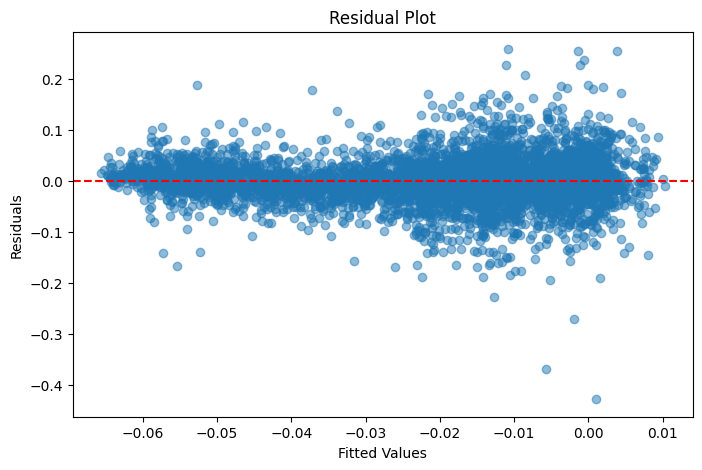

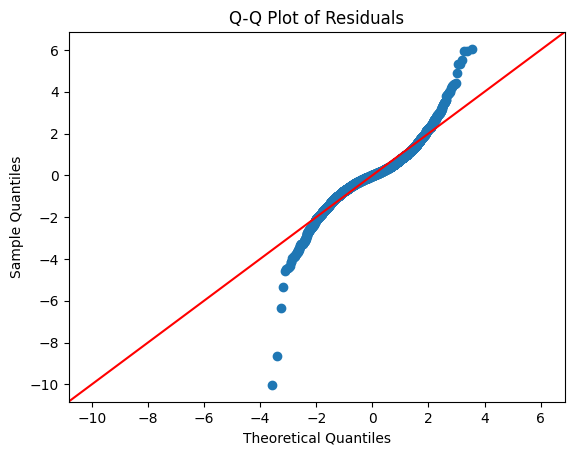

Variance Inflation Factors (VIF):
             Feature        VIF
0          Intercept   0.000000
1          treatment   4.507417
2               post   8.174372
3     treatment_post   7.656768
4            est_twh  12.090794
5            min_twh  12.423404
6          marketCap   5.420564
7          GoldPrice   3.845637
8           OilPrice   2.654812
9         volatility   1.530593
10  market_sentiment   1.031947

Breusch-Pagan test results:
Lagrange multiplier statistic: 522.9320276369984
p-value: 5.531871341283887e-106
f-value: 57.577491381321124
f p-value: 2.0242248958137452e-111

Jarque-Bera test results:
JB Statistic: 9715.083723625812
p-value: 0.0
Skew: -0.13503190053231637
Kurtosis: 9.453300299363987


d:\anaconda\envs\shap\Lib\site-packages\statsmodels\regression\linear_model.py:1782: RuntimeWarning: divide by zero encountered in scalar divide
  return 1 - self.ssr/self.centered_tss


In [1]:
import pandas as pd
import statsmodels.formula.api as smf
import statsmodels.api as sm
import matplotlib.pyplot as plt
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import jarque_bera

# 1. Load ETH and BTC datasets and parse the 'Date' column
df_eth = pd.read_csv("eth_mergeddata_feature.csv", parse_dates=['Date'])
df_btc = pd.read_csv("btc_mergeddata_feature.csv", parse_dates=['Date'])

# 2. Add a coin identifier for each dataset
df_eth['coin'] = 'ETH'
df_btc['coin'] = 'BTC'

# 3. Concatenate both datasets into one DataFrame
df = pd.concat([df_eth, df_btc], ignore_index=True)

# 4. Create a treatment variable: ETH is the treatment group (treatment=1), BTC is the control group (treatment=0)
df['treatment'] = (df['coin'] == 'ETH').astype(int)

# 5. Create a time dummy variable: post = 1 for dates on or after September 15, 2022
df['post'] = (df['Date'] >= pd.to_datetime("2022-09-15")).astype(int)

# 6. Create the DID interaction term: treatment multiplied by post
df['treatment_post'] = df['treatment'] * df['post']

# 7. Rename energy consumption variables for ease of use (ensure the names match your data exactly)
df = df.rename(columns={
    'Estimated TWh per Year': 'est_twh',
    'Minimum TWh per Year': 'min_twh'
})

# 8. List of control variables (ensure these variables exist in your dataset)
# control_vars = ['marketCap', 'GoldPrice', 'SP500Price', 'OilPrice', 'volatility', 'MA5', 'market_sentiment']
control_vars = ['marketCap', 'GoldPrice', 'OilPrice', 'volatility', 'market_sentiment']
controls_formula = " + ".join(control_vars)

# 9. Build the DID regression formula.
# The coefficient on treatment_post represents the DID effect, i.e. the net effect on return_riskfree of the ETH transition (compared to BTC)
formula = f'return_riskfree ~ treatment + post + treatment_post + est_twh + min_twh + {controls_formula}'

# 10. Fit the regression model
model = smf.ols(formula, data=df).fit()

# 11. Output the regression summary
print(model.summary())

# 12. Model Diagnostics

# 12.1 Fit a model with heteroskedasticity robust standard errors (HC3)
model_robust = smf.ols(formula, data=df).fit(cov_type='HC3')
print(model_robust.summary())

# 12.2 Residual plot: Check if the residuals are randomly scattered
plt.figure(figsize=(8, 5))
plt.scatter(model.fittedvalues, model.resid, alpha=0.5)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Fitted Values')
plt.ylabel('Residuals')
plt.title('Residual Plot')
plt.show()

# 12.3 Q-Q Plot: Check if the residuals follow a normal distribution
sm.qqplot(model.resid, line='45', fit=True)
plt.title('Q-Q Plot of Residuals')
plt.show()

# 12.4 Multicollinearity check: Calculate VIF for each independent variable
X = model.model.exog  # Retrieve the design matrix (including intercept)
vif_data = pd.DataFrame()
vif_data['Feature'] = model.model.exog_names
vif_data['VIF'] = [variance_inflation_factor(X, i) for i in range(X.shape[1])]
print("Variance Inflation Factors (VIF):")
print(vif_data)

# 12.5 Heteroskedasticity test: Breusch-Pagan test
bp_test = het_breuschpagan(model.resid, model.model.exog)
bp_labels = ['Lagrange multiplier statistic', 'p-value', 'f-value', 'f p-value']
print("\nBreusch-Pagan test results:")
for label, value in zip(bp_labels, bp_test):
    print(f"{label}: {value}")

# 12.6 Normality test: Jarque-Bera test
jb_stat, jb_pvalue, skew, kurtosis = jarque_bera(model.resid)
print("\nJarque-Bera test results:")
print(f"JB Statistic: {jb_stat}")
print(f"p-value: {jb_pvalue}")
print(f"Skew: {skew}")
print(f"Kurtosis: {kurtosis}")


LASSO Regression (with CV) Results:
Selected alpha: 1.6116871769891704e-05
             Feature  Coefficient
0          treatment    -0.007971
1               post    -0.011385
2     treatment_post    -0.006688
3            est_twh     0.003063
4            min_twh    -0.010423
5          marketCap     0.045723
6          GoldPrice     0.007806
7         SP500Price    -0.009046
8           OilPrice    -0.007853
9         volatility    -0.000180
10               MA5    -0.040594
11  market_sentiment    -0.001160
LASSO Test MSE: 0.0018420464189846388
LASSO Test R2: 0.1688787510970784


d:\anaconda\envs\shap\Lib\site-packages\sklearn\model_selection\_validation.py:528: FitFailedWarning: 
15 fits failed out of a total of 50.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
12 fits failed with the following error:
Traceback (most recent call last):
  File "d:\anaconda\envs\shap\Lib\site-packages\sklearn\model_selection\_validation.py", line 866, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "d:\anaconda\envs\shap\Lib\site-packages\sklearn\base.py", line 1382, in wrapper
    estimator._validate_params()
  File "d:\anaconda\envs\shap\Lib\site-packages\sklearn\base.py", line 436, in _validate_params
    validate_parameter_constraints(
  File "d:\anaconda\envs\shap\Lib\site-packages\sklearn\utils\_


Random Forest RandomizedSearchCV Results:
Best Parameters: {'n_estimators': 100, 'min_samples_split': 5, 'min_samples_leaf': 4, 'max_features': 'sqrt', 'max_depth': 10}
Best CV Score (neg MSE): -0.001782225321209624

Best Random Forest Test Results:
RF Test MSE: 0.0018664241365223971
RF Test R2: 0.15787965854622277

Feature Importances from Best Random Forest Model:
             Feature  Importance
1               post    0.131983
8           OilPrice    0.127294
4            min_twh    0.117204
6          GoldPrice    0.105130
5          marketCap    0.092647
7         SP500Price    0.090702
9         volatility    0.088001
3            est_twh    0.080264
10               MA5    0.071765
11  market_sentiment    0.068777
2     treatment_post    0.023967
0          treatment    0.002265


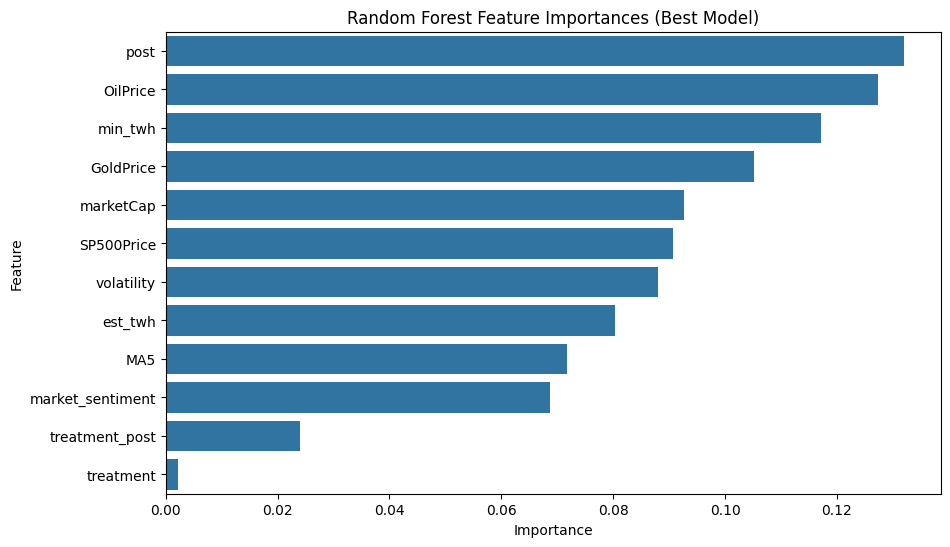


[Additional Comments]
1. A large coefficient for 'treatment_post' in LASSO indicates that the DID effect remains important after regularization.
2. Random Forest feature importance ranking helps assess each variable's impact on return_riskfree; if 'treatment_post' is significant, it supports the DID conclusion.
3. Randomized parameter search further optimizes the RF model via cross-validation, enhancing its predictive performance and interpretability.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LassoCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

# 1. Data Loading and Preprocessing
df_eth = pd.read_csv("eth_mergeddata_feature.csv", parse_dates=['Date'])
df_btc = pd.read_csv("btc_mergeddata_feature.csv", parse_dates=['Date'])
df_eth['coin'] = 'ETH'
df_btc['coin'] = 'BTC'
df = pd.concat([df_eth, df_btc], ignore_index=True)

# Create treatment, post, and DID interaction variables
df['treatment'] = (df['coin'] == 'ETH').astype(int)
df['post'] = (df['Date'] >= pd.to_datetime("2022-09-15")).astype(int)
df['treatment_post'] = df['treatment'] * df['post']

# Rename energy consumption variables (ensure these match your dataset)
df = df.rename(columns={
    'Estimated TWh per Year': 'est_twh',
    'Minimum TWh per Year': 'min_twh'
})

# Control variables list (verify these columns exist)
control_vars = ['marketCap', 'GoldPrice', 'SP500Price', 'OilPrice', 'volatility', 'MA5', 'market_sentiment']
features = ['treatment', 'post', 'treatment_post', 'est_twh', 'min_twh'] + control_vars

# Define target variable
y = df['return_riskfree']
X = df[features].copy()

# 2. Split Data (80% train, 20% test) and Standardize features (helpful for LASSO)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 3. LASSO Regression with Cross-Validation
lasso_cv = LassoCV(cv=5, random_state=42, max_iter=10000)
lasso_cv.fit(X_train_scaled, y_train)
print("LASSO Regression (with CV) Results:")
print("Selected alpha:", lasso_cv.alpha_)
coef_df = pd.DataFrame({'Feature': features, 'Coefficient': lasso_cv.coef_})
print(coef_df)
y_pred_lasso = lasso_cv.predict(X_test_scaled)
print("LASSO Test MSE:", mean_squared_error(y_test, y_pred_lasso))
print("LASSO Test R2:", r2_score(y_test, y_pred_lasso))

# 4. Random Forest with Randomized Parameter Search
param_dist = {
    'n_estimators': [10, 30, 50, 100, 300],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['auto', 'sqrt', 'log2']
}
rf = RandomForestRegressor(random_state=42)
random_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_dist,
    n_iter=10,      # Adjust as needed
    cv=5,
    scoring='neg_mean_squared_error',
    n_jobs=-1,
    random_state=42
)
random_search.fit(X_train, y_train)
print("\nRandom Forest RandomizedSearchCV Results:")
print("Best Parameters:", random_search.best_params_)
print("Best CV Score (neg MSE):", random_search.best_score_)
best_rf = random_search.best_estimator_
y_pred_rf = best_rf.predict(X_test)
print("\nBest Random Forest Test Results:")
print("RF Test MSE:", mean_squared_error(y_test, y_pred_rf))
print("RF Test R2:", r2_score(y_test, y_pred_rf))

# Feature importance from best RF model
rf_importance = pd.DataFrame({
    'Feature': features,
    'Importance': best_rf.feature_importances_
}).sort_values(by='Importance', ascending=False)
print("\nFeature Importances from Best Random Forest Model:")
print(rf_importance)
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=rf_importance)
plt.title("Random Forest Feature Importances (Best Model)")
plt.show()

# 5. Additional Comments
print("\n[Additional Comments]")
print("1. A large coefficient for 'treatment_post' in LASSO indicates that the DID effect remains important after regularization.")
print("2. Random Forest feature importance ranking helps assess each variable's impact on return_riskfree; if 'treatment_post' is significant, it supports the DID conclusion.")
print("3. Randomized parameter search further optimizes the RF model via cross-validation, enhancing its predictive performance and interpretability.")
